# Text Clustering and Topic Modeling

Devon Farber | Boston University MET CS688 coursework

Cleans Indiegogo campaign titles, compares bag-of-words preprocessing, applies TF-IDF, LSA, K-means, and LDA, and visualizes topic probabilities.

## Results and reproducibility
Recorded output: vocabulary reduced from 20,750 to 4,880 terms (76.48%); LSA plus K-means silhouette score 0.659. This internal clustering score is not predictive accuracy or proof of topic quality. Requires the five original indiegogo_2025_06.csv through indiegogo_2025_10.csv files, which are not included.

Saved outputs are retained from the submitted notebook. This portfolio packaging did not rerun the analysis.

See the repository README for setup and input requirements.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving indiegogo_2025_10.csv to indiegogo_2025_10.csv
Saving indiegogo_2025_09.csv to indiegogo_2025_09.csv
Saving indiegogo_2025_08.csv to indiegogo_2025_08.csv
Saving indiegogo_2025_07.csv to indiegogo_2025_07.csv
Saving indiegogo_2025_06.csv to indiegogo_2025_06.csv


In [ ]:
import pandas as pd
import os

In [ ]:
csv_files = [file for file in os.listdir() if file.endswith('.csv')]

print("Number of CSV files found:", len(csv_files))

for file in sorted(csv_files):
    print(file)

Number of CSV files found: 5
indiegogo_2025_06.csv
indiegogo_2025_07.csv
indiegogo_2025_08.csv
indiegogo_2025_09.csv
indiegogo_2025_10.csv


In [ ]:
dataframes = []

for file in sorted(csv_files):
    df = pd.read_csv(file)
    dataframes.append(df)

    print("\nFile:", file)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


File: indiegogo_2025_06.csv
Rows: 31164
Columns: 26

File: indiegogo_2025_07.csv
Rows: 31297
Columns: 26

File: indiegogo_2025_08.csv
Rows: 31259
Columns: 26

File: indiegogo_2025_09.csv
Rows: 31182
Columns: 26

File: indiegogo_2025_10.csv
Rows: 28587
Columns: 26


In [ ]:
print(dataframes[0].columns.tolist())

['bullet_point', 'category', 'category_url', 'clickthrough_url', 'close_date', 'currency', 'funds_raised_amount', 'funds_raised_percent', 'image_url', 'is_indemand', 'is_pre_launch', 'is_promoted', 'is_proven', 'offered_by', 'open_date', 'perk_goal_percentage', 'perks_claimed', 'price_offered', 'price_retail', 'product_stage', 'project_id', 'project_type', 'source_url', 'tagline', 'tags', 'title']


In [ ]:
dataframes[0].head()

,bullet_point,category,category_url,clickthrough_url,close_date,currency,funds_raised_amount,funds_raised_percent,image_url,is_indemand,...,perks_claimed,price_offered,price_retail,product_stage,project_id,project_type,source_url,tagline,tags,title
0,NaN,Wellness,/explore/wellness,/projects/unigym-all-in-one-home-gym-for-stren...,2024-11-18T23:59:59-08:00,EUR,45402,5.287250,https://c1.iggcdn.com/indiegogo-media-prod-cld...,True,...,NaN,506.0,0.0,NaN,3032118,campaign,https://www.indiegogo.com/explore/all?project_...,"Expertly Designed to Relieve Hand, Back, and K...","[""sports"",""family"",""yoga"",""women"",""smart home""]",UniGym:All-in-One Home Gym for Strength & Well...
1,NaN,Wellness,/explore/wellness,/projects/chonkers,2020-11-10T23:59:59-08:00,USD,37766,2.133267,https://c1.iggcdn.com/indiegogo-media-prod-cld...,True,...,NaN,39.0,50.0,NaN,2640574,campaign,https://www.indiegogo.com/explore/all?project_...,Chubby teddy bears to help manage anxiety with...,"[""design"",""pillows"",""sleep"",""toys"",""women""]",Chonkers
2,NaN,Wellness,/explore/wellness,/projects/cafe-extra-ordinaire-cafe-with-a-twist,2025-07-08T23:59:59-07:00,CAD,20,0.000100,https://c1.iggcdn.com/indiegogo-media-prod-cld...,False,...,NaN,14.0,0.0,NaN,3284990,campaign,https://www.indiegogo.com/explore/all?project_...,A café and life skills centre for individuals ...,"[""community"",""female founders"",""coffee"",""resta...",Café EXTRA Ordinaire - Café With A Twist
3,NaN,Wellness,/explore/wellness,/projects/easy-flosser,2019-12-18T23:59:59-08:00,USD,29523,2.771900,https://c1.iggcdn.com/indiegogo-media-prod-cld...,True,...,NaN,29.0,40.0,NaN,2566311,campaign,https://www.indiegogo.com/explore/all?project_...,"Use any brand of floss, Reach back teeth easil...","[""family"",""beauty""]",Easy Flosser
4,NaN,Wellness,/explore/wellness,/projects/30-day-bible-verse-challenge,2025-06-17T23:59:59-07:00,USD,10,0.002857,https://c1.iggcdn.com/indiegogo-media-prod-cld...,False,...,NaN,10.0,15.0,NaN,3289789,campaign,https://www.indiegogo.com/explore/all?project_...,"A 30 day faith-based activity where you color,...","[""animation"",""books"",""community"",""family"",""kids""]",30 Day Bible Verse Challenge


In [ ]:
for i, column in enumerate(dataframes[0].columns):
    print(i, column)

0 bullet_point
1 category
2 category_url
3 clickthrough_url
4 close_date
5 currency
6 funds_raised_amount
7 funds_raised_percent
8 image_url
9 is_indemand
10 is_pre_launch
11 is_promoted
12 is_proven
13 offered_by
14 open_date
15 perk_goal_percentage
16 perks_claimed
17 price_offered
18 price_retail
19 product_stage
20 project_id
21 project_type
22 source_url
23 tagline
24 tags
25 title


In [ ]:
[col for col in dataframes[0].columns
 if 'title' in col.lower() or 'name' in col.lower()]

['title']

In [ ]:
combined_df = pd.concat(dataframes, ignore_index=True)

print("Total rows before cleaning:", combined_df.shape[0])
print("Total columns:", combined_df.shape[1])

Total rows before cleaning: 153489
Total columns: 26


In [ ]:
titles_df = combined_df[['title']].copy()

titles_df.head()

,title
0,UniGym:All-in-One Home Gym for Strength & Well...
1,Chonkers
2,Café EXTRA Ordinaire - Café With A Twist
3,Easy Flosser
4,30 Day Bible Verse Challenge


In [ ]:
titles_df = titles_df.dropna(subset=['title'])

titles_df['title'] = titles_df['title'].astype(str).str.strip()

titles_df = titles_df[titles_df['title'] != '']

print("Titles after removing missing/blank values:", len(titles_df))

Titles after removing missing/blank values: 153489


In [ ]:
print("Titles before duplicate removal:", len(titles_df))

titles_df = titles_df.drop_duplicates(subset=['title']).reset_index(drop=True)

print("Unique titles after duplicate removal:", len(titles_df))

Titles before duplicate removal: 153489
Unique titles after duplicate removal: 19875


In [ ]:
titles_df.head(10)

,title
0,UniGym:All-in-One Home Gym for Strength & Well...
1,Chonkers
2,Café EXTRA Ordinaire - Café With A Twist
3,Easy Flosser
4,30 Day Bible Verse Challenge
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...
6,Mental Wellness with AI-Driven EEG & VR Therapy
7,Sponsor Free Therapy for NYC Teens & Adults
8,Power Play Kids Gym - Strength Through Fun
9,Cows 4 Kids


In [ ]:
print("Final number of unique titles:", len(titles_df))

Final number of unique titles: 19875


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
bow_vectorizer = CountVectorizer(
    lowercase=False
)

bow_matrix = bow_vectorizer.fit_transform(titles_df['title'])

print("Bag of Words matrix created.")

Bag of Words matrix created.


In [ ]:
lowercase=False

In [ ]:
print("Number of documents:", bow_matrix.shape[0])
print("Number of unique terms:", bow_matrix.shape[1])
print("Matrix shape:", bow_matrix.shape)

Number of documents: 19875
Number of unique terms: 20750
Matrix shape: (19875, 20750)


In [ ]:
feature_names = bow_vectorizer.get_feature_names_out()

print("First 50 terms:")
print(feature_names[:50])

First 50 terms:
['00' '000' '0000' '0000120' '0001' '000mAh' '001' '003' '0033' '007' '01'
 '01X' '02' '021' '03' '04' '05' '052' '058' '06' '07' '08' '0854'
 '08verified' '09' '0909' '10' '100' '1000' '1000R' '1000W' '1000w'
 '100Sites' '100W' '100Website' '100km' '100mg' '100verify' '100ᴍɢ' '101'
 '1024' '103' '104' '106' '108' '10Best' '10Buy' '10K' '10Top'
 '10_Nice_sites_to_Buy_Old_']


In [ ]:
total_cells = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_cells = bow_matrix.nnz

sparsity = 1 - (nonzero_cells / total_cells)

print("Total matrix cells:", total_cells)
print("Non-zero cells:", nonzero_cells)
print("Matrix sparsity:", round(sparsity * 100, 2), "%")

Total matrix cells: 412406250
Non-zero cells: 122488
Matrix sparsity: 99.97 %


In [ ]:
bow_sample = pd.DataFrame(
    bow_matrix[:10, :20].toarray(),
    columns=feature_names[:20]
)

bow_sample

,00,000,0000,0000120,0001,000mAh,001,003,0033,007,01,01X,02,021,03,04,05,052,058,06
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
import re

titles_df['clean_title'] = titles_df['title'].str.lower()

titles_df['clean_title'] = titles_df['clean_title'].apply(
    lambda x: re.sub(r'[^a-z\s]', ' ', x)
)

titles_df['clean_title'] = titles_df['clean_title'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

titles_df[['title', 'clean_title']].head(10)

,title,clean_title
0,UniGym:All-in-One Home Gym for Strength & Well...,unigym all in one home gym for strength wellness
1,Chonkers,chonkers
2,Café EXTRA Ordinaire - Café With A Twist,caf extra ordinaire caf with a twist
3,Easy Flosser,easy flosser
4,30 Day Bible Verse Challenge,day bible verse challenge
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,yhe bp doctor fit gen blood pressure smartwatch
6,Mental Wellness with AI-Driven EEG & VR Therapy,mental wellness with ai driven eeg vr therapy
7,Sponsor Free Therapy for NYC Teens & Adults,sponsor free therapy for nyc teens adults
8,Power Play Kids Gym - Strength Through Fun,power play kids gym strength through fun
9,Cows 4 Kids,cows kids


In [ ]:
titles_clean = titles_df[titles_df['clean_title'] != ''].copy()

print("Titles remaining after text normalization:", len(titles_clean))

Titles remaining after text normalization: 19495


In [ ]:
bow_normalized = CountVectorizer()

normalized_matrix = bow_normalized.fit_transform(
    titles_clean['clean_title']
)

print("Documents:", normalized_matrix.shape[0])
print("Unique terms after normalization:", normalized_matrix.shape[1])
print("Matrix shape:", normalized_matrix.shape)

Documents: 19495
Unique terms after normalization: 15375
Matrix shape: (19495, 15375)


In [ ]:
total_cells_normalized = (
    normalized_matrix.shape[0] * normalized_matrix.shape[1]
)

nonzero_cells_normalized = normalized_matrix.nnz

sparsity_normalized = 1 - (
    nonzero_cells_normalized / total_cells_normalized
)

print("Total matrix cells:", total_cells_normalized)
print("Non-zero cells:", nonzero_cells_normalized)
print(
    "Matrix sparsity:",
    round(sparsity_normalized * 100, 2),
    "%"
)

Total matrix cells: 299735625
Non-zero cells: 115780
Matrix sparsity: 99.96 %


In [ ]:
print("BEFORE TEXT NORMALIZATION")
print("Unique terms:", bow_matrix.shape[1])
print("Sparsity:", round(sparsity * 100, 2), "%")

print("\nAFTER TEXT NORMALIZATION")
print("Unique terms:", normalized_matrix.shape[1])
print("Sparsity:", round(sparsity_normalized * 100, 2), "%")

BEFORE TEXT NORMALIZATION
Unique terms: 20750
Sparsity: 99.97 %

AFTER TEXT NORMALIZATION
Unique terms: 15375
Sparsity: 99.96 %


In [ ]:
normalized_terms = bow_normalized.get_feature_names_out()

print("First 50 normalized terms:")
print(normalized_terms[:50])

First 50 normalized terms:
['aaa' 'aaccounts' 'aadhira' 'aadongle' 'aai' 'aand' 'aar' 'aaron'
 'aavaaz' 'aawireless' 'ab' 'abandoned' 'abandonment' 'abc' 'abccounts'
 'abducted' 'abee' 'abi' 'abide' 'abigail' 'ability' 'ableton' 'abolish'
 'abomination' 'about' 'above' 'aboveground' 'abroad' 'abrumpere'
 'absalom' 'absence' 'absent' 'absolute' 'absolutely' 'absolution'
 'absorb' 'absorbency' 'absurd' 'abu' 'abuelas' 'abundance' 'abuse'
 'abusive' 'abxylute' 'abyss' 'ac' 'acacia' 'academy' 'acc' 'accaount']


In [ ]:
bow_stopwords = CountVectorizer(
    stop_words='english'
)

stopword_matrix = bow_stopwords.fit_transform(
    titles_clean['clean_title']
)

print("Documents:", stopword_matrix.shape[0])
print("Unique terms after stop-word removal:", stopword_matrix.shape[1])
print("Matrix shape:", stopword_matrix.shape)

Documents: 19495
Unique terms after stop-word removal: 15139
Matrix shape: (19495, 15139)


In [ ]:
total_cells_stopwords = (
    stopword_matrix.shape[0] * stopword_matrix.shape[1]
)

nonzero_cells_stopwords = stopword_matrix.nnz

sparsity_stopwords = 1 - (
    nonzero_cells_stopwords / total_cells_stopwords
)

print("Total matrix cells:", total_cells_stopwords)
print("Non-zero cells:", nonzero_cells_stopwords)
print(
    "Matrix sparsity:",
    round(sparsity_stopwords * 100, 2),
    "%"
)

Total matrix cells: 295134805
Non-zero cells: 92184
Matrix sparsity: 99.97 %


In [ ]:
print("ORIGINAL BAG OF WORDS")
print("Unique terms:", bow_matrix.shape[1])
print("Sparsity:", round(sparsity * 100, 2), "%")

print("\nAFTER TEXT NORMALIZATION")
print("Unique terms:", normalized_matrix.shape[1])
print("Sparsity:", round(sparsity_normalized * 100, 2), "%")

print("\nAFTER STOP-WORD REMOVAL")
print("Unique terms:", stopword_matrix.shape[1])
print("Sparsity:", round(sparsity_stopwords * 100, 2), "%")

ORIGINAL BAG OF WORDS
Unique terms: 20750
Sparsity: 99.97 %

AFTER TEXT NORMALIZATION
Unique terms: 15375
Sparsity: 99.96 %

AFTER STOP-WORD REMOVAL
Unique terms: 15139
Sparsity: 99.97 %


In [ ]:
stopword_terms = bow_stopwords.get_feature_names_out()

print("First 50 terms after stop-word removal:")
print(stopword_terms[:50])

First 50 terms after stop-word removal:
['aaa' 'aaccounts' 'aadhira' 'aadongle' 'aai' 'aand' 'aar' 'aaron'
 'aavaaz' 'aawireless' 'ab' 'abandoned' 'abandonment' 'abc' 'abccounts'
 'abducted' 'abee' 'abi' 'abide' 'abigail' 'ability' 'ableton' 'abolish'
 'abomination' 'aboveground' 'abroad' 'abrumpere' 'absalom' 'absence'
 'absent' 'absolute' 'absolutely' 'absolution' 'absorb' 'absorbency'
 'absurd' 'abu' 'abuelas' 'abundance' 'abuse' 'abusive' 'abxylute' 'abyss'
 'ac' 'acacia' 'academy' 'acc' 'accaount' 'acccluster' 'accelerate']


In [ ]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

lemmatizer = WordNetLemmatizer()

stop_words = set(ENGLISH_STOP_WORDS)

In [ ]:
def lemmatize_title(text):
    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    lemmas = [
        lemmatizer.lemmatize(
            lemmatizer.lemmatize(word, pos='v'),
            pos='n'
        )
        for word in words
    ]

    return ' '.join(lemmas)

In [ ]:
titles_clean['lemma_title'] = titles_clean['clean_title'].apply(
    lemmatize_title
)

titles_clean[['title', 'clean_title', 'lemma_title']].head(10)

,title,clean_title,lemma_title
0,UniGym:All-in-One Home Gym for Strength & Well...,unigym all in one home gym for strength wellness,unigym home gym strength wellness
1,Chonkers,chonkers,chonkers
2,Café EXTRA Ordinaire - Café With A Twist,caf extra ordinaire caf with a twist,caf extra ordinaire caf twist
3,Easy Flosser,easy flosser,easy flosser
4,30 Day Bible Verse Challenge,day bible verse challenge,day bible verse challenge
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,yhe bp doctor fit gen blood pressure smartwatch,yhe bp doctor fit gen blood pressure smartwatch
6,Mental Wellness with AI-Driven EEG & VR Therapy,mental wellness with ai driven eeg vr therapy,mental wellness ai drive eeg vr therapy
7,Sponsor Free Therapy for NYC Teens & Adults,sponsor free therapy for nyc teens adults,sponsor free therapy nyc teen adult
8,Power Play Kids Gym - Strength Through Fun,power play kids gym strength through fun,power play kid gym strength fun
9,Cows 4 Kids,cows kids,cow kid


In [ ]:
titles_lemma = titles_clean[
    titles_clean['lemma_title'] != ''
].copy()

print(
    "Titles remaining after lemmatization:",
    len(titles_lemma)
)

Titles remaining after lemmatization: 19468


In [ ]:
titles_lemma = titles_clean[
    titles_clean['lemma_title'] != ''
].copy()

print(
    "Titles remaining after lemmatization:",
    len(titles_lemma)
)

Titles remaining after lemmatization: 19468


In [ ]:
bow_lemma = CountVectorizer()

lemma_matrix = bow_lemma.fit_transform(
    titles_lemma['lemma_title']
)

print("Documents:", lemma_matrix.shape[0])
print("Unique terms after lemmatization:", lemma_matrix.shape[1])
print("Matrix shape:", lemma_matrix.shape)

Documents: 19468
Unique terms after lemmatization: 13382
Matrix shape: (19468, 13382)


In [ ]:
total_cells_lemma = (
    lemma_matrix.shape[0] * lemma_matrix.shape[1]
)

nonzero_cells_lemma = lemma_matrix.nnz

sparsity_lemma = 1 - (
    nonzero_cells_lemma / total_cells_lemma
)

print("Total matrix cells:", total_cells_lemma)
print("Non-zero cells:", nonzero_cells_lemma)
print(
    "Matrix sparsity:",
    round(sparsity_lemma * 100, 2),
    "%"
)

Total matrix cells: 260520776
Non-zero cells: 92044
Matrix sparsity: 99.96 %


In [ ]:
print("ORIGINAL BAG OF WORDS")
print("Unique terms:", bow_matrix.shape[1])
print("Sparsity:", round(sparsity * 100, 2), "%")

print("\nAFTER TEXT NORMALIZATION")
print("Unique terms:", normalized_matrix.shape[1])
print("Sparsity:", round(sparsity_normalized * 100, 2), "%")

print("\nAFTER STOP-WORD REMOVAL")
print("Unique terms:", stopword_matrix.shape[1])
print("Sparsity:", round(sparsity_stopwords * 100, 2), "%")

print("\nAFTER LEMMATIZATION")
print("Unique terms:", lemma_matrix.shape[1])
print("Sparsity:", round(sparsity_lemma * 100, 2), "%")

ORIGINAL BAG OF WORDS
Unique terms: 20750
Sparsity: 99.97 %

AFTER TEXT NORMALIZATION
Unique terms: 15375
Sparsity: 99.96 %

AFTER STOP-WORD REMOVAL
Unique terms: 15139
Sparsity: 99.97 %

AFTER LEMMATIZATION
Unique terms: 13382
Sparsity: 99.96 %


In [ ]:
lemma_terms = bow_lemma.get_feature_names_out()

print("First 50 terms after lemmatization:")
print(lemma_terms[:50])

First 50 terms after lemmatization:
['aaa' 'aaccounts' 'aadhira' 'aadongle' 'aai' 'aand' 'aar' 'aaron'
 'aavaaz' 'aawireless' 'ab' 'abandon' 'abandonment' 'abc' 'abccounts'
 'abduct' 'abee' 'abi' 'abide' 'abigail' 'ability' 'ableton' 'abolish'
 'abomination' 'aboveground' 'abroad' 'abrumpere' 'absalom' 'absence'
 'absent' 'absolute' 'absolutely' 'absolution' 'absorb' 'absorbency'
 'absurd' 'abu' 'abuelas' 'abundance' 'abuse' 'abusive' 'abxylute' 'abyss'
 'ac' 'acacia' 'academy' 'acc' 'accaount' 'acccluster' 'accelerate']


In [ ]:
bow_filtered = CountVectorizer(
    min_df=2
)

filtered_matrix = bow_filtered.fit_transform(
    titles_lemma['lemma_title']
)

print("Documents:", filtered_matrix.shape[0])
print("Unique terms after rare-term filtering:", filtered_matrix.shape[1])
print("Matrix shape:", filtered_matrix.shape)

Documents: 19468
Unique terms after rare-term filtering: 4880
Matrix shape: (19468, 4880)


In [ ]:
min_df=2

In [ ]:
total_cells_filtered = (
    filtered_matrix.shape[0] * filtered_matrix.shape[1]
)

nonzero_cells_filtered = filtered_matrix.nnz

sparsity_filtered = 1 - (
    nonzero_cells_filtered / total_cells_filtered
)

print("Total matrix cells:", total_cells_filtered)
print("Non-zero cells:", nonzero_cells_filtered)
print(
    "Matrix sparsity:",
    round(sparsity_filtered * 100, 2),
    "%"
)

Total matrix cells: 95003840
Non-zero cells: 83542
Matrix sparsity: 99.91 %


In [ ]:
print("ORIGINAL BAG OF WORDS")
print("Unique terms:", bow_matrix.shape[1])
print("Sparsity:", round(sparsity * 100, 2), "%")

print("\nAFTER TEXT NORMALIZATION")
print("Unique terms:", normalized_matrix.shape[1])
print("Sparsity:", round(sparsity_normalized * 100, 2), "%")

print("\nAFTER STOP-WORD REMOVAL")
print("Unique terms:", stopword_matrix.shape[1])
print("Sparsity:", round(sparsity_stopwords * 100, 2), "%")

print("\nAFTER LEMMATIZATION")
print("Unique terms:", lemma_matrix.shape[1])
print("Sparsity:", round(sparsity_lemma * 100, 2), "%")

print("\nAFTER RARE-TERM FILTERING")
print("Unique terms:", filtered_matrix.shape[1])
print("Sparsity:", round(sparsity_filtered * 100, 2), "%")

ORIGINAL BAG OF WORDS
Unique terms: 20750
Sparsity: 99.97 %

AFTER TEXT NORMALIZATION
Unique terms: 15375
Sparsity: 99.96 %

AFTER STOP-WORD REMOVAL
Unique terms: 15139
Sparsity: 99.97 %

AFTER LEMMATIZATION
Unique terms: 13382
Sparsity: 99.96 %

AFTER RARE-TERM FILTERING
Unique terms: 4880
Sparsity: 99.91 %


In [ ]:
filtered_terms = bow_filtered.get_feature_names_out()

print("First 50 terms after rare-term filtering:")
print(filtered_terms[:50])

First 50 terms after rare-term filtering:
['abandon' 'abc' 'abroad' 'abu' 'abyss' 'ac' 'acacia' 'academy' 'acc'
 'accelerate' 'acceptance' 'access' 'accessory' 'acco' 'accommodation'
 'accou' 'accoun' 'account' 'accountfor' 'accountsbtc' 'accountsin'
 'accouts' 'accurate' 'ace' 'achieve' 'achilles' 'acid' 'acount' 'acounts'
 'acquire' 'acquisition' 'act' 'action' 'activate' 'active' 'activewear'
 'activity' 'actor' 'actually' 'ad' 'adam' 'adaptable' 'adaptation'
 'adapter' 'add' 'adderall' 'additional' 'address' 'adelaide' 'adhd']


In [ ]:
original_terms = bow_matrix.shape[1]
final_terms = filtered_matrix.shape[1]

reduction = original_terms - final_terms
reduction_percent = (reduction / original_terms) * 100

print("Original vocabulary size:", original_terms)
print("Final vocabulary size:", final_terms)
print("Terms removed:", reduction)
print("Vocabulary reduction:", round(reduction_percent, 2), "%")

Original vocabulary size: 20750
Final vocabulary size: 4880
Terms removed: 15870
Vocabulary reduction: 76.48 %


In [ ]:
from sklearn.feature_extraction.text import TfidfTransformer

In [ ]:
tfidf_transformer = TfidfTransformer()

tfidf_matrix = tfidf_transformer.fit_transform(
    filtered_matrix
)

print("TF-IDF matrix created.")
print("Matrix shape:", tfidf_matrix.shape)

TF-IDF matrix created.
Matrix shape: (19468, 4880)


In [ ]:
print("Number of documents:", tfidf_matrix.shape[0])
print("Number of terms:", tfidf_matrix.shape[1])
print("Non-zero TF-IDF values:", tfidf_matrix.nnz)

Number of documents: 19468
Number of terms: 4880
Non-zero TF-IDF values: 83542


In [ ]:
tfidf_sample = pd.DataFrame(
    tfidf_matrix[:10, :20].toarray(),
    columns=filtered_terms[:20]
)

tfidf_sample.round(3)

,abandon,abc,abroad,abu,abyss,ac,acacia,academy,acc,accelerate,acceptance,access,accessory,acco,accommodation,accou,accoun,account,accountfor,accountsbtc
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
first_doc = tfidf_matrix[0]

scores = first_doc.toarray().flatten()

top_indices = scores.argsort()[-10:][::-1]

print("Title:")
print(titles_lemma.iloc[0]['title'])

print("\nTop TF-IDF terms:")

for index in top_indices:
    if scores[index] > 0:
        print(
            filtered_terms[index],
            round(scores[index], 3)
        )

Title:
UniGym:All-in-One Home Gym for Strength & Wellness

Top TF-IDF terms:
strength 0.58
gym 0.52
wellness 0.489
home 0.393


In [ ]:
from sklearn.decomposition import TruncatedSVD

In [ ]:
n_topics = 5

lsa_model = TruncatedSVD(
    n_components=n_topics,
    random_state=42
)

lsa_matrix = lsa_model.fit_transform(tfidf_matrix)

print("LSA completed.")
print("Original TF-IDF shape:", tfidf_matrix.shape)
print("LSA matrix shape:", lsa_matrix.shape)

LSA completed.
Original TF-IDF shape: (19468, 4880)
LSA matrix shape: (19468, 5)


In [ ]:
print("Explained variance by topic:")

for i, variance in enumerate(lsa_model.explained_variance_ratio_):
    print(
        f"Topic {i + 1}:",
        round(variance * 100, 2),
        "%"
    )

print(
    "\nTotal explained variance:",
    round(
        lsa_model.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

Explained variance by topic:
Topic 1: 4.48 %
Topic 2: 2.46 %
Topic 3: 1.49 %
Topic 4: 1.22 %
Topic 5: 1.05 %

Total explained variance: 10.7 %


In [ ]:
def display_lsa_topics(model, feature_names, n_top_words=10):
    for topic_idx, topic in enumerate(model.components_):

        top_indices = topic.argsort()[-n_top_words:][::-1]

        top_words = [
            feature_names[i]
            for i in top_indices
        ]

        print(
            f"Topic {topic_idx + 1}:",
            ", ".join(top_words)
        )

display_lsa_topics(
    lsa_model,
    filtered_terms,
    n_top_words=10
)

Topic 1: account, buy, verify, cash, app, best, sit, old, gmail, usa
Topic 2: app, cash, verify, btc, place, secure, enable, platform, web, reliable
Topic 3: old, gmail, app, cash, new, pva, age, bulk, github, guide
Topic 4: best, sit, app, cash, pva, place, age, google, bulk, review
Topic 5: film, short, horror, feature, student, fund, comedy, thesis, independent, documentary


In [ ]:
import numpy as np

lsa_clusters = np.argmax(
    np.abs(lsa_matrix),
    axis=1
) + 1

titles_lemma['LSA_cluster'] = lsa_clusters

titles_lemma[
    ['title', 'LSA_cluster']
].head(10)

,title,LSA_cluster
0,UniGym:All-in-One Home Gym for Strength & Well...,5
1,Chonkers,1
2,Café EXTRA Ordinaire - Café With A Twist,5
3,Easy Flosser,4
4,30 Day Bible Verse Challenge,5
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,5
6,Mental Wellness with AI-Driven EEG & VR Therapy,5
7,Sponsor Free Therapy for NYC Teens & Adults,5
8,Power Play Kids Gym - Strength Through Fun,5
9,Cows 4 Kids,5


In [ ]:
lsa_cluster_counts = (
    titles_lemma['LSA_cluster']
    .value_counts()
    .sort_index()
)

print("Campaigns in each LSA cluster:")
print(lsa_cluster_counts)

Campaigns in each LSA cluster:
LSA_cluster
1    8070
2     807
3    1221
4    2617
5    6753
Name: count, dtype: int64


In [ ]:
for cluster in sorted(
    titles_lemma['LSA_cluster'].unique()
):

    print(f"\nLSA CLUSTER {cluster}")

    examples = titles_lemma[
        titles_lemma['LSA_cluster'] == cluster
    ]['title'].head(5)

    for title in examples:
        print("-", title)


LSA CLUSTER 1
- Chonkers
- FEARITE
- reCOVAry
- MyPet’s Horoscope
- LuxeDerm

LSA CLUSTER 2
- Chris76 All Natural Eczema Cream Title
- She Sails Mobile App - Explore For Peace & Purpose
- Financial Wellness: Asset Flex
- Golden Web Retreat in Portugal
- Help us Bring Mojo Mapper and Match Mater App Live

LSA CLUSTER 3
- Kismmet: Find Local Connection
- 1991999 ND Drink
- Real-world billboard mockups for augmented reality
- A 247 self-service Launderette
- Bigger, Bolder, Better: A New Paradox Awaits

LSA CLUSTER 4
- Easy Flosser
- HhPatch - A treatment for Over-Active Sweat Glands
- Agriturismo culturale Santa Barbara
- DaMembrane- Dermatologists Guided Skincare Brand
- Ascend – Where Breath, Awareness & AI Guide

LSA CLUSTER 5
- UniGym:All-in-One Home Gym for Strength & Wellness
- Café EXTRA Ordinaire - Café With A Twist
- 30 Day Bible Verse Challenge
- YHE BP Doctor Fit: Gen 3 Blood Pressure Smartwatch
- Mental Wellness with AI-Driven EEG & VR Therapy


In [ ]:
from sklearn.cluster import KMeans

kmeans_lsa = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

lsa_kmeans_clusters = kmeans_lsa.fit_predict(lsa_matrix)

print("K-means clustering on LSA completed.")

K-means clustering on LSA completed.


In [ ]:
titles_lemma['LSA_KMeans_cluster'] = lsa_kmeans_clusters + 1

titles_lemma[
    ['title', 'LSA_KMeans_cluster']
].head(10)

,title,LSA_KMeans_cluster
0,UniGym:All-in-One Home Gym for Strength & Well...,2
1,Chonkers,2
2,Café EXTRA Ordinaire - Café With A Twist,2
3,Easy Flosser,2
4,30 Day Bible Verse Challenge,2
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,2
6,Mental Wellness with AI-Driven EEG & VR Therapy,2
7,Sponsor Free Therapy for NYC Teens & Adults,2
8,Power Play Kids Gym - Strength Through Fun,2
9,Cows 4 Kids,2


In [ ]:
for cluster in sorted(
    titles_lemma['LSA_KMeans_cluster'].unique()
):

    print(f"\nLSA + K-MEANS CLUSTER {cluster}")

    examples = titles_lemma[
        titles_lemma['LSA_KMeans_cluster'] == cluster
    ]['title'].head(8)

    for title in examples:
        print("-", title)


LSA + K-MEANS CLUSTER 1
- Fund FLOWERS Film
- Rainbow Roll-up Shorts 2.0 AKA The Rudest Shorts
- Eco Shorts: The most environmentally friendly
- Let Her Stay - An Independent Student Short Film
- I'm Back Film
- AFAR: An Interactive Horror Film - PRE ORDER
- Scar - A Western Short Film
- All In - Short Film

LSA + K-MEANS CLUSTER 2
- UniGym:All-in-One Home Gym for Strength & Wellness
- Chonkers
- Café EXTRA Ordinaire - Café With A Twist
- Easy Flosser
- 30 Day Bible Verse Challenge
- YHE BP Doctor Fit: Gen 3 Blood Pressure Smartwatch
- Mental Wellness with AI-Driven EEG & VR Therapy
- Sponsor Free Therapy for NYC Teens & Adults

LSA + K-MEANS CLUSTER 3
- Buy, Verified Mexc Accounts 2025 To Top Places -
- 2.0 Top 16 Site To Buy Verified Onlyfans Creator
- Now You Can Buy, Verified Alipay() Accounts - 2025
- 3 Best Sites to Buy Hotmail Accounts (Bulk & Aged)
- Where can I Buy,, verified Apple Pay accounts-2025
- Looking to buy verified 2checkout account ready to
- How To Buy Verified Ne

In [ ]:
cluster_term_weights = (
    kmeans_lsa.cluster_centers_
    @ lsa_model.components_
)

for cluster_idx, weights in enumerate(cluster_term_weights):

    top_indices = weights.argsort()[-10:][::-1]

    top_words = [
        filtered_terms[i]
        for i in top_indices
    ]

    print(
        f"Cluster {cluster_idx + 1}:",
        ", ".join(top_words)
    )

Cluster 1: film, short, horror, feature, student, fund, comedy, thesis, independent, documentary
Cluster 2: account, buy, verify, film, old, short, gmail, usa, paypal, sit
Cluster 3: account, buy, verify, best, sit, paypal, site, usa, wise, cashapp
Cluster 4: app, cash, verify, account, buy, best, sit, place, new, old
Cluster 5: gmail, old, account, buy, sit, pva, age, best, new, bulk


In [ ]:
from sklearn.metrics import silhouette_score

lsa_silhouette = silhouette_score(
    lsa_matrix,
    lsa_kmeans_clusters
)

print(
    "LSA + K-means silhouette score:",
    round(lsa_silhouette, 3)
)

LSA + K-means silhouette score: 0.659


In [ ]:
filtered_matrix

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 83542 stored elements and shape (19468, 4880)>

In [ ]:
from sklearn.decomposition import LatentDirichletAllocation

In [ ]:
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method='batch',
    max_iter=20
)

lda_matrix = lda_model.fit_transform(filtered_matrix)

print("LDA completed.")
print("Original count matrix shape:", filtered_matrix.shape)
print("LDA topic matrix shape:", lda_matrix.shape)


LDA completed.
Original count matrix shape: (19468, 4880)
LDA topic matrix shape: (19468, 5)


In [ ]:
def display_lda_topics(model, feature_names, n_top_words=10):

    for topic_idx, topic in enumerate(model.components_):

        top_indices = topic.argsort()[-n_top_words:][::-1]

        top_words = [
            feature_names[i]
            for i in top_indices
        ]

        print(
            f"Topic {topic_idx + 1}:",
            ", ".join(top_words)
        )

display_lda_topics(
    lda_model,
    filtered_terms,
    n_top_words=10
)

Topic 1: film, short, horror, support, feature, world, project, fund, help, book
Topic 2: account, buy, verify, best, sit, site, usa, place, facebook, paypal
Topic 3: account, buy, app, cash, verify, old, gmail, new, sit, pva
Topic 4: online, buy, delivery, fast, order, ship, home, xanax, number, ambien
Topic 5: help, album, smart, new, life, ai, music, world, future, game


In [ ]:
lda_clusters = lda_matrix.argmax(axis=1) + 1

titles_lemma['LDA_topic'] = lda_clusters

titles_lemma[
    ['title', 'LDA_topic']
].head(10)

,title,LDA_topic
0,UniGym:All-in-One Home Gym for Strength & Well...,4
1,Chonkers,1
2,Café EXTRA Ordinaire - Café With A Twist,3
3,Easy Flosser,5
4,30 Day Bible Verse Challenge,2
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,5
6,Mental Wellness with AI-Driven EEG & VR Therapy,4
7,Sponsor Free Therapy for NYC Teens & Adults,4
8,Power Play Kids Gym - Strength Through Fun,4
9,Cows 4 Kids,4


In [ ]:
lda_topic_counts = (
    titles_lemma['LDA_topic']
    .value_counts()
    .sort_index()
)

print("Campaigns in each LDA topic:")
print(lda_topic_counts)

Campaigns in each LDA topic:
LDA_topic
1    4388
2    4534
3    3607
4    3272
5    3667
Name: count, dtype: int64


In [ ]:
for topic in sorted(
    titles_lemma['LDA_topic'].unique()
):

    print(f"\nLDA TOPIC {topic}")

    examples = titles_lemma[
        titles_lemma['LDA_topic'] == topic
    ]['title'].head(8)

    for title in examples:
        print("-", title)


LDA TOPIC 1
- Chonkers
- Natures Silence
- Mixscape: Sleep, Mindful, Flow, Mixed Soundscapes
- FEARITE
- DaMembrane- Dermatologists Guided Skincare Brand
- reCOVAry
- Unlock Your Potential & Turn Dreams into Reality!
- MyPet’s Horoscope

LDA TOPIC 2
- 30 Day Bible Verse Challenge
- Buy, Verified Mexc Accounts 2025 To Top Places -
- Now You Can Buy, Verified Alipay() Accounts - 2025
- 3 Best Sites to Buy Hotmail Accounts (Bulk & Aged)
- Where can I Buy,, verified Apple Pay accounts-2025
- Looking to buy verified 2checkout account ready to
- job value
- Beyond Business: Empowering Entrepreneurs

LDA TOPIC 3
- Café EXTRA Ordinaire - Café With A Twist
- 1991999 ND Drink
- Ascend – Where Breath, Awareness & AI Guide
- 2.0 Top 16 Site To Buy Verified Onlyfans Creator
- Stepping Through Application
- nazerke top nurhan bot
- Artisanal Market on the Move
- Bigger, Bolder, Better: A New Paradox Awaits

LDA TOPIC 4
- UniGym:All-in-One Home Gym for Strength & Wellness
- Mental Wellness with AI-D

In [ ]:
print("Title:")
print(titles_lemma.iloc[0]['title'])

print("\nTopic probabilities:")

for i, probability in enumerate(lda_matrix[0]):
    print(
        f"Topic {i + 1}:",
        round(probability, 3)
    )

Title:
UniGym:All-in-One Home Gym for Strength & Wellness

Topic probabilities:
Topic 1: 0.041
Topic 2: 0.04
Topic 3: 0.04
Topic 4: 0.839
Topic 5: 0.04


In [ ]:
titles_lemma['LDA_probability'] = lda_matrix.max(axis=1)

titles_lemma[
    ['title', 'LDA_topic', 'LDA_probability']
].head(10)

,title,LDA_topic,LDA_probability
0,UniGym:All-in-One Home Gym for Strength & Well...,4,0.839480
1,Chonkers,1,0.200000
2,Café EXTRA Ordinaire - Café With A Twist,3,0.836904
3,Easy Flosser,5,0.399411
4,30 Day Bible Verse Challenge,2,0.549501
5,YHE BP Doctor Fit: Gen 3 Blood Pressure Smartw...,5,0.571469
6,Mental Wellness with AI-Driven EEG & VR Therapy,4,0.899043
7,Sponsor Free Therapy for NYC Teens & Adults,4,0.422550
8,Power Play Kids Gym - Strength Through Fun,4,0.514821
9,Cows 4 Kids,4,0.401040


In [ ]:
selected_indices = []

for topic in range(1, 6):

    topic_indices = titles_lemma[
        titles_lemma['LDA_topic'] == topic
    ].nlargest(
        5,
        'LDA_probability'
    ).index

    selected_indices.extend(topic_indices)

print("Number of titles selected:", len(selected_indices))

Number of titles selected: 25


In [ ]:
selected_titles = titles_lemma.loc[
    selected_indices,
    ['title', 'LDA_topic', 'LDA_probability']
]

selected_titles

,title,LDA_topic,LDA_probability
2362,Rose N Gold - Solid Brass EDC Keychain Cigar S...,1,0.910680
11779,Fred Perry's GD COLOR Gold Brick Volume 3 & 4,1,0.899998
13381,Steve Ditko zine YOU DON'T KNOW DITKO issue #2,1,0.899985
11774,Fred Perry's Gold Digger COLOR Gold Brick 10,1,0.899972
16872,GIRL SCOUT & TOMBOY: A Horror-Thriller Short Film,1,0.899959
15593,"Best Site To Buy Facebook Accounts USA, UK, CA",2,0.910943
553,"Buy Google Voice Accounts---Smmmarketusa,USA,U...",2,0.910902
12688,"Buy, Facebook Ads Accounts In USA UK CA Verified",2,0.910897
3092,USA Buy Verified CashApp Account - 100% USA UK CA,2,0.910862
4079,USA 44 Best Site To Buy USA Facebook Accounts ...,2,0.910850


In [ ]:
heatmap_data = lda_matrix[selected_indices, :]

print("Heatmap data shape:", heatmap_data.shape)

Heatmap data shape: (25, 5)


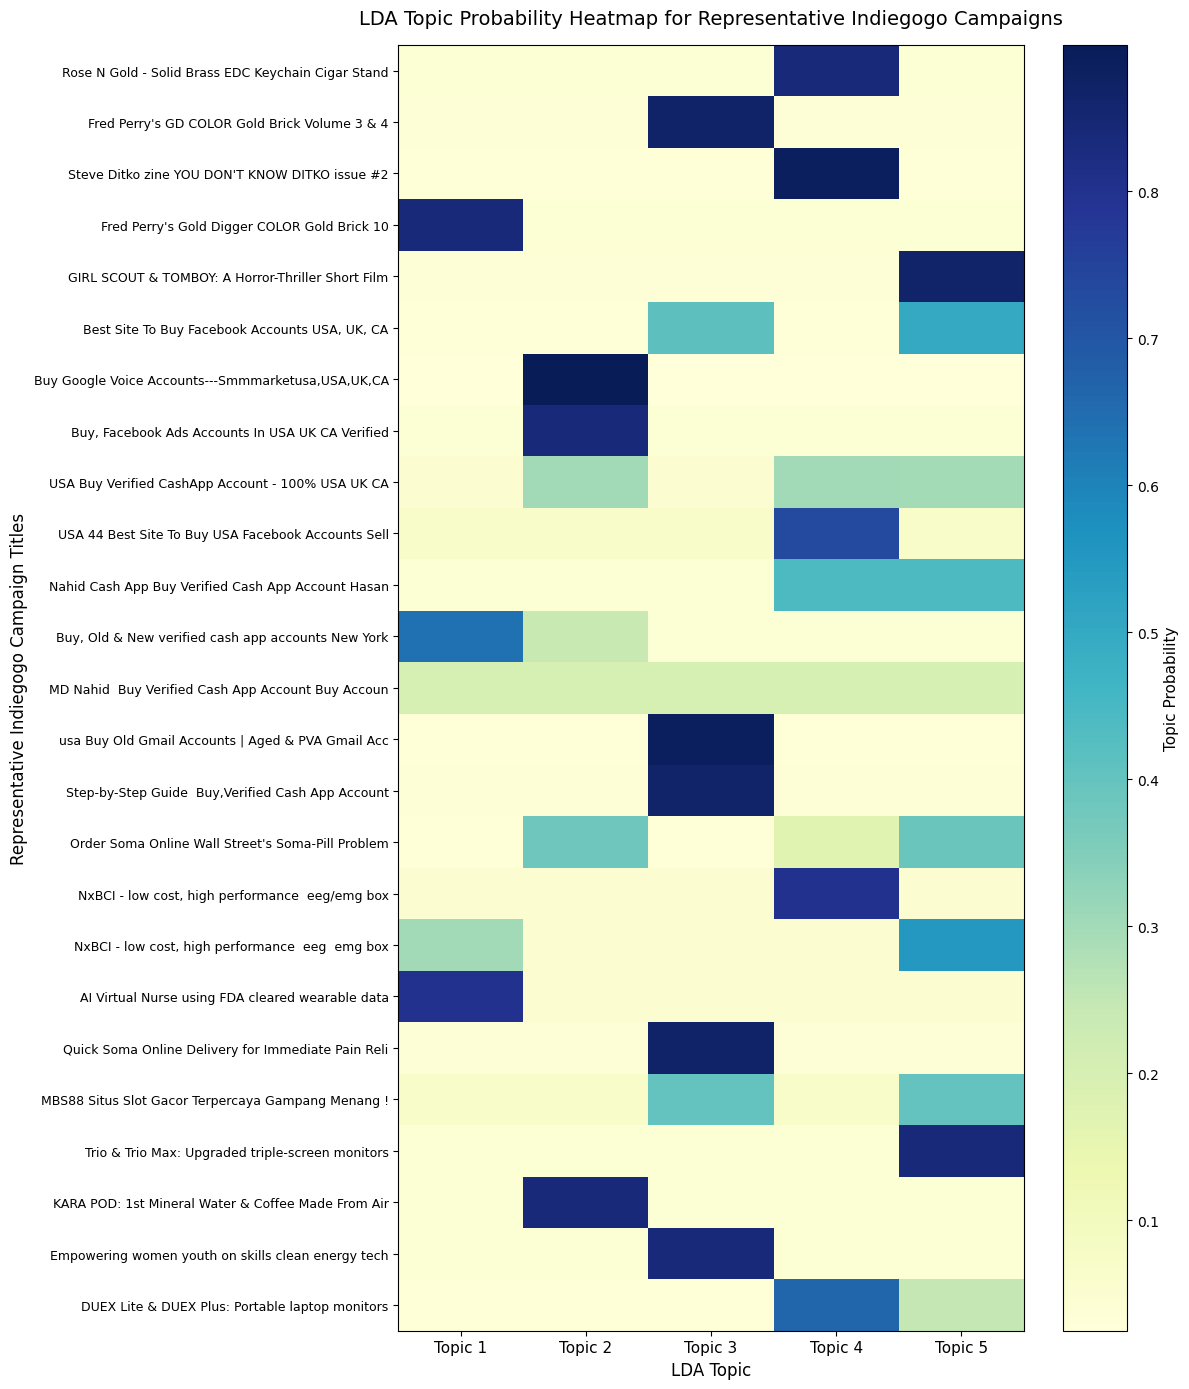

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 14))

heatmap = ax.imshow(
    heatmap_data,
    aspect='auto',
    cmap='YlGnBu'
)

ax.set_xticks(np.arange(5))
ax.set_xticklabels(
    ['Topic 1', 'Topic 2', 'Topic 3', 'Topic 4', 'Topic 5'],
    fontsize=11
)

short_titles = [
    title[:55] + '...' if len(title) > 55 else title
    for title in selected_titles['title']
]

ax.set_yticks(np.arange(len(short_titles)))
ax.set_yticklabels(
    short_titles,
    fontsize=9
)

ax.set_xlabel(
    'LDA Topic',
    fontsize=12
)

ax.set_ylabel(
    'Representative Indiegogo Campaign Titles',
    fontsize=12
)

ax.set_title(
    'LDA Topic Probability Heatmap for Representative Indiegogo Campaigns',
    fontsize=14,
    pad=15
)

cbar = plt.colorbar(
    heatmap,
    ax=ax
)

cbar.set_label(
    'Topic Probability',
    fontsize=11
)

plt.tight_layout()

fig.savefig(
    "CS688_Homework3_LDA_Heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

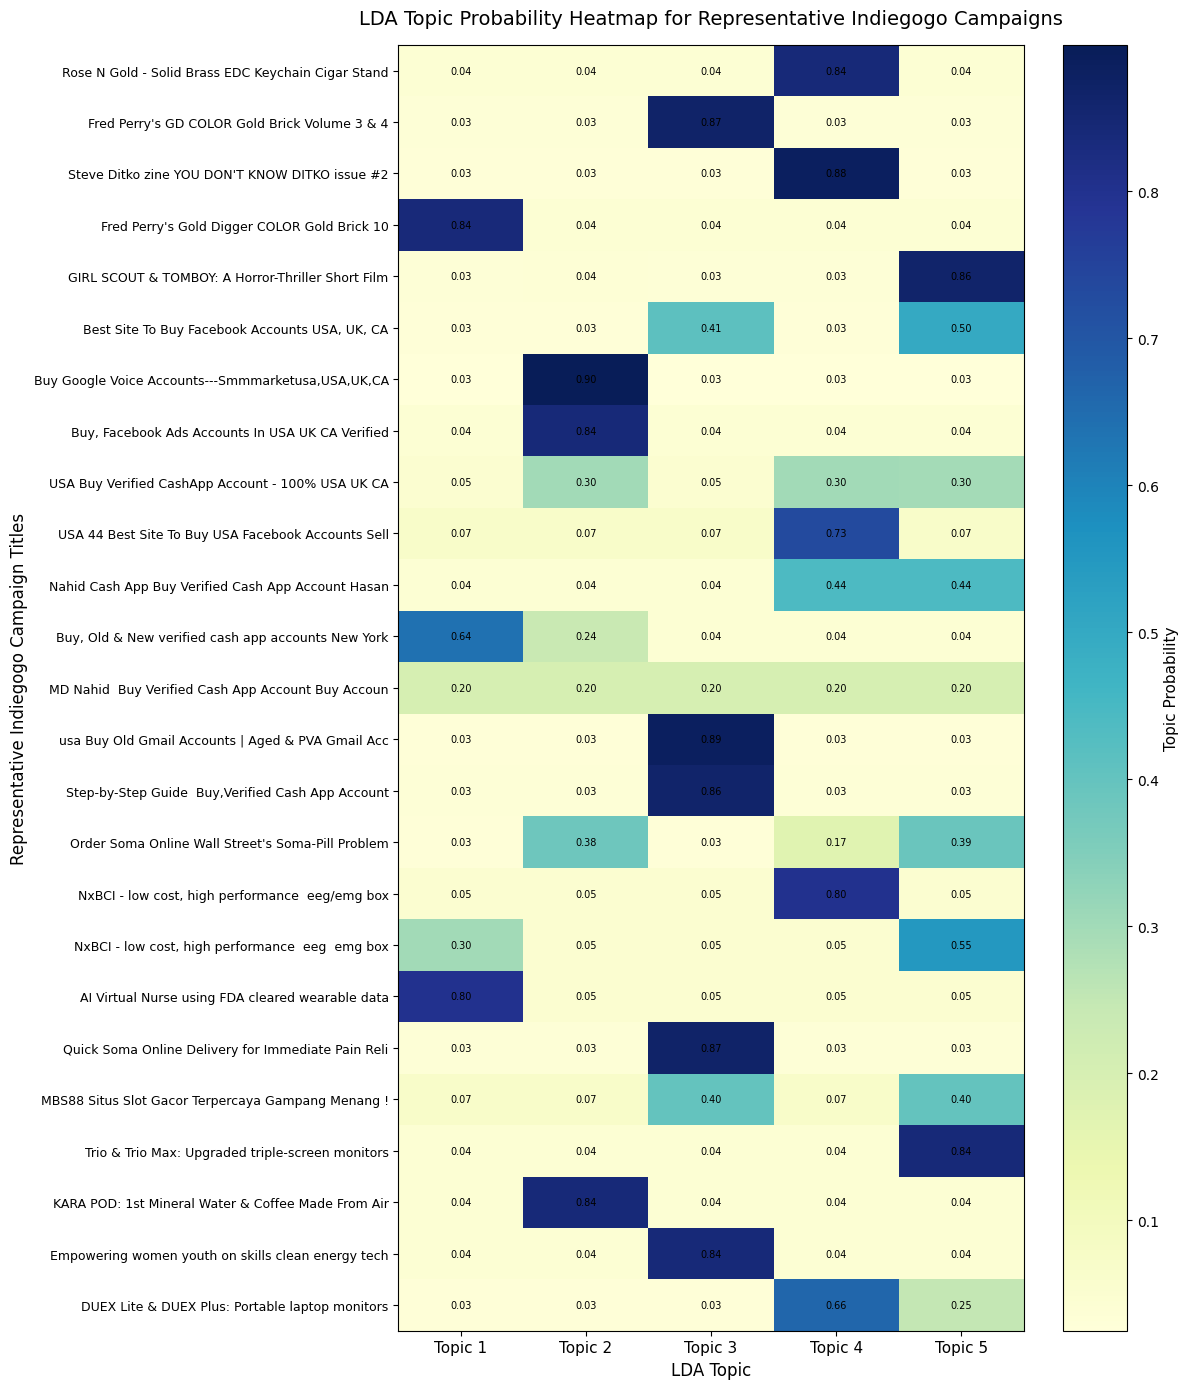

In [ ]:
fig, ax = plt.subplots(figsize=(12, 14))

heatmap = ax.imshow(
    heatmap_data,
    aspect='auto',
    cmap='YlGnBu'
)

ax.set_xticks(np.arange(5))
ax.set_xticklabels(
    ['Topic 1', 'Topic 2', 'Topic 3', 'Topic 4', 'Topic 5'],
    fontsize=11
)

ax.set_yticks(np.arange(len(short_titles)))
ax.set_yticklabels(
    short_titles,
    fontsize=9
)

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):

        value = heatmap_data[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha='center',
            va='center',
            fontsize=7
        )

ax.set_xlabel(
    'LDA Topic',
    fontsize=12
)

ax.set_ylabel(
    'Representative Indiegogo Campaign Titles',
    fontsize=12
)

ax.set_title(
    'LDA Topic Probability Heatmap for Representative Indiegogo Campaigns',
    fontsize=14,
    pad=15
)

cbar = plt.colorbar(
    heatmap,
    ax=ax
)

cbar.set_label(
    'Topic Probability',
    fontsize=11
)

plt.tight_layout()
plt.show()

In [ ]:
plt.show()

In [ ]:
plt.savefig(
    "CS688_Homework3_LDA_Heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.tight_layout()

plt.savefig(
    "CS688_Homework3_LDA_Heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

<Figure size 640x480 with 0 Axes>